<a href="https://colab.research.google.com/github/ashwinkck/SME-1-/blob/main/upes/GenAI/UPES_genai_05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install tensorflow matplotlib numpy

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Dense,
    Flatten,
    Reshape,
    LeakyReLU,
    Dropout
)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# Check if CUDA (GPU) is available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

In [ ]:
(x_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

print("Dataset shape:", x_train.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Dataset shape: (60000, 28, 28)


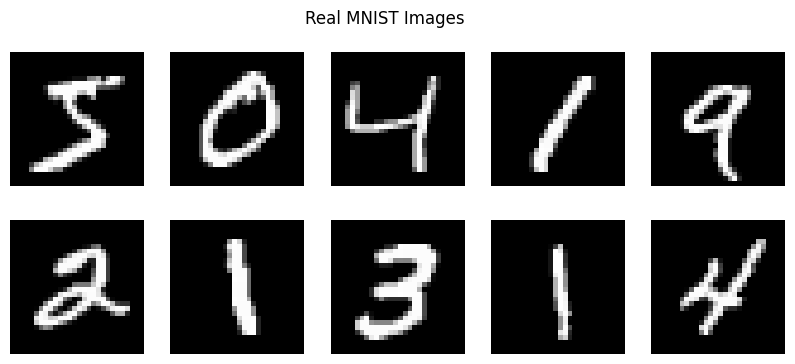

In [ ]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.axis("off")

plt.suptitle("Real MNIST Images")
plt.show()

In [ ]:
x_train = x_train.astype("float32")

x_train = (x_train - 127.5) / 127.5

x_train = x_train.reshape(-1, 28, 28, 1)

print("Normalized shape:", x_train.shape)
print("Minimum:", x_train.min())
print("Maximum:", x_train.max())

Normalized shape: (60000, 28, 28, 1)
Minimum: -1.0
Maximum: 1.0


In [ ]:
noise_dim = 100

generator = Sequential([
    Dense(256, input_shape=(noise_dim,)),
    LeakyReLU(negative_slope=0.2),

    Dense(512),
    LeakyReLU(negative_slope=0.2),

    Dense(1024),
    LeakyReLU(negative_slope=0.2),

    Dense(28 * 28, activation="tanh"),
    Reshape((28, 28, 1))
])

generator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       803,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,486,352 (5.67 MB)

 Trainable params: 1,486,352 (5.67 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
discriminator = Sequential([
    Flatten(input_shape=(28, 28, 1)),

    Dense(512),
    LeakyReLU(negative_slope=0.2),
    Dropout(0.3),

    Dense(256),
    LeakyReLU(negative_slope=0.2),
    Dropout(0.3),

    Dense(1, activation="sigmoid")
])

discriminator.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 533,505 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
cross_entropy = tf.keras.losses.BinaryCrossentropy()

generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5
)

In [ ]:
def discriminator_loss(real_output, fake_output):

    real_loss = cross_entropy(
        tf.ones_like(real_output),
        real_output
    )

    fake_loss = cross_entropy(
        tf.zeros_like(fake_output),
        fake_output
    )

    return real_loss + fake_loss


def generator_loss(fake_output):

    return cross_entropy(
        tf.ones_like(fake_output),
        fake_output
    )

In [ ]:
@tf.function
def train_step(real_images):

    batch_size = tf.shape(real_images)[0]

    noise = tf.random.normal(
        [batch_size, noise_dim]
    )

    # Train the Discriminator
    with tf.GradientTape() as disc_tape:

        generated_images = tf.stop_gradient(
            generator(noise, training=True)
        )

        real_output = discriminator(
            real_images,
            training=True
        )

        fake_output = discriminator(
            generated_images,
            training=True
        )

        d_loss = discriminator_loss(
            real_output,
            fake_output
        )

    disc_gradients = disc_tape.gradient(
        d_loss,
        discriminator.trainable_variables
    )

    discriminator_optimizer.apply_gradients(
        zip(
            disc_gradients,
            discriminator.trainable_variables
        )
    )

    # Train the Generator
    noise = tf.random.normal(
        [batch_size, noise_dim]
    )

    with tf.GradientTape() as gen_tape:

        generated_images = generator(
            noise,
            training=True
        )

        fake_output = discriminator(
            generated_images,
            training=True
        )

        g_loss = generator_loss(fake_output)

    gen_gradients = gen_tape.gradient(
        g_loss,
        generator.trainable_variables
    )

    generator_optimizer.apply_gradients(
        zip(
            gen_gradients,
            generator.trainable_variables
        )
    )

    return d_loss, g_loss

In [ ]:
batch_size = 128

train_dataset = (
    tf.data.Dataset
    .from_tensor_slices(x_train)
    .shuffle(60000)
    .batch(batch_size, drop_remainder=True)
)

In [ ]:
epochs = 30

for epoch in range(epochs):

    for image_batch in train_dataset:

        d_loss, g_loss = train_step(image_batch)

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Discriminator Loss: {d_loss:.4f} | "
        f"Generator Loss: {g_loss:.4f}"
    )

Epoch 1/30 | Discriminator Loss: 1.3192 | Generator Loss: 0.8543
Epoch 2/30 | Discriminator Loss: 1.1584 | Generator Loss: 1.2318
Epoch 3/30 | Discriminator Loss: 1.0409 | Generator Loss: 1.4151
Epoch 4/30 | Discriminator Loss: 1.0070 | Generator Loss: 1.4751
Epoch 5/30 | Discriminator Loss: 0.9387 | Generator Loss: 1.3225


In [ ]:
def generate_images(model, number=10):

    noise = tf.random.normal(
        [number, noise_dim]
    )

    predictions = model(
        noise,
        training=False
    )

    predictions = (predictions + 1) / 2

    plt.figure(figsize=(12, 4))

    for i in range(number):

        plt.subplot(2, 5, i + 1)

        plt.imshow(
            predictions[i, :, :, 0],
            cmap="gray"
        )

        plt.axis("off")

    plt.suptitle("Images Generated by GAN")
    plt.show()


generate_images(generator)

### PyTorch Implementation with CUDA
Since we want to leverage CUDA for faster training, let's implement the GAN training step and models using PyTorch.

In [ ]:
# 1. Define PyTorch Models
class PyTorchGenerator(nn.Module):
    def __init__(self, noise_dim):
        super(PyTorchGenerator, self).__init__()
        self.model = nn.Sequential(
            nn.Linear(noise_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 1024),
            nn.LeakyReLU(0.2),
            nn.Linear(1024, 28 * 28),
            nn.Tanh()
        )

    def forward(self, x):
        return self.model(x).view(-1, 1, 28, 28)

class PyTorchDiscriminator(nn.Module):
    def __init__(self):
        super(PyTorchDiscriminator, self).__init__()
        self.model = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.model(x)

# Instantiate and move models to CUDA
pyt_generator = PyTorchGenerator(noise_dim).to(device)
pyt_discriminator = PyTorchDiscriminator().to(device)

criterion = nn.BCELoss()
g_optimizer = optim.Adam(pyt_generator.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = optim.Adam(pyt_discriminator.parameters(), lr=0.0002, betas=(0.5, 0.999))

In [ ]:
# 2. Prepare PyTorch DataLoader
x_train_pt = torch.tensor(x_train).permute(0, 3, 1, 2).float()
dataset = TensorDataset(x_train_pt)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

In [ ]:
# 3. PyTorch Training Loop using CUDA
epochs = 5  # Demonstrating with 5 epochs

for epoch in range(epochs):
    for i, (real_imgs,) in enumerate(dataloader):
        real_imgs = real_imgs.to(device)
        curr_batch_size = real_imgs.size(0)

        # Labels
        real_labels = torch.ones(curr_batch_size, 1, device=device)
        fake_labels = torch.zeros(curr_batch_size, 1, device=device)

        # --- Train Discriminator ---
        d_optimizer.zero_grad()

        # Real loss
        outputs = pyt_discriminator(real_imgs)
        d_loss_real = criterion(outputs, real_labels)

        # Fake loss
        noise = torch.randn(curr_batch_size, noise_dim, device=device)
        fake_imgs = pyt_generator(noise)
        outputs = pyt_discriminator(fake_imgs.detach())
        d_loss_fake = criterion(outputs, fake_labels)

        d_loss = d_loss_real + d_loss_fake
        d_loss.backward()
        d_optimizer.step()

        # --- Train Generator ---
        g_optimizer.zero_grad()

        outputs = pyt_discriminator(fake_imgs)
        g_loss = criterion(outputs, real_labels)

        g_loss.backward()
        g_optimizer.step()

    print(f"Epoch [{epoch+1}/{epochs}] | Discriminator Loss: {d_loss.item():.4f} | Generator Loss: {g_loss.item():.4f}")